# Growth Sequential — Kernel, Constrained (Uno)

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

This notebook solves the same problem as the companion ridgeless
notebook, but with a **constrained optimizer**: the interior-point
solver [Uno](https://github.com/cvanaret/Uno) through `unopy`, with JAX
supplying the gradient, Jacobian, and Hessian callbacks. Structural
parameters stay plain module-level constants — the NLP solver is
host-side C++, so nothing rides through a differentiable `p` here.

In [2]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import unopy

Structural parameters: the Aruoba–Fernández-Villaverde–Rubio-Ramírez
calibration, with the continuous discount rate mapped from the quarterly
anchor $e^{-\hat\rho/4} = \beta$.

In [3]:
a = 1.0 / 3.0  # capital share in f(k) = k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
k_0 = 1.0  # initial capital

Parameters of the algorithm: the kernel hyperparameters, the collocation
and test grids, and the domain floor for the interior point.

In [4]:
ELL = 10.0  # Matern-1/2 length scale
SIGMA = 1.0  # kernel amplitude
TRAIN_T = 100.0
N_TRAIN = 101
TEST_T = 110.0
N_TEST = 100
TVC_T = 200.0
DOMAIN_EPS = 1e-6  # domain floor for the interior point's infeasible iterates

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)

## The model

The planner problem and its Pontryagin conditions are exactly those of
the ridgeless notebook: with costate $\mu$,

$$k'(t) = k(t)^a - \delta k(t) - c(t),
\qquad
\mu'(t) = -\mu(t)\big(a\, k(t)^{a-1} - \delta - \hat\rho\big),
\qquad
\mu(t) = c(t)^{-\sigma},$$

with $k(0) = k_0$ pinned, $(c_0, \mu_0)$ free, no terminal condition,
and transversality verified after the fact. Each of the three paths
$(\mu, c, k)$ is an integrated Matérn-1/2 expansion

$$x(t) = x(0) + \sum_j \alpha_j \tilde K(t, t_j),
\qquad
x'(t) = \sum_j \alpha_j k(t, t_j),$$

with $k(t, t') = \sigma^2 e^{-|t-t'|/\ell}$,
$h(d) = \sigma^2 \ell (1 - e^{-d/\ell})$, and
$\tilde K(t_i, t_j) = h(t_j) + \operatorname{sign}(t_i - t_j) h(|t_i - t_j|)$.

In [5]:
def antiderivative(d):
    return SIGMA**2 * ELL * (1.0 - jnp.exp(-d / ELL))


def kernel_matrices(t_i, t_j):
    s = t_i[:, None] - t_j[None, :]
    K = SIGMA**2 * jnp.exp(-jnp.abs(s) / ELL)
    K_tilde = antiderivative(t_j)[None, :] + jnp.sign(s) * antiderivative(jnp.abs(s))
    return K, K_tilde

## The constrained program

The ridgeless notebook reaches the minimum-norm interpolant as the
$\lambda \to 0$ limit of the penalized least squares. The
constrained-optimizer implementation solves that limit **exactly**, as
the nonlinear program

$$\min_{\alpha_\mu, \alpha_c, \alpha_k,\, c_0, \mu_0}\
\alpha_\mu^\top K \alpha_\mu + \alpha_c^\top K \alpha_c + \alpha_k^\top K \alpha_k
\quad \text{s.t.} \quad
\begin{aligned}
&k' - \big(k^a - \delta k - c\big) = 0, \\
&\mu' + \mu\big(a k^{a-1} - \delta - \hat\rho\big) = 0, \\
&\mu c^\sigma - 1 = 0,
\end{aligned}$$

at every training date, plus the positivity constraints
$k, c, \mu \ge \varepsilon$ — the interior point evaluates infeasible
trial iterates, so $k$ also clamps at $\varepsilon$ inside the model
functions. JAX supplies `jax.grad`,
[`jax.jacfwd`](https://docs.jax.dev/en/latest/automatic-differentiation.html),
and the Lagrangian Hessian via `jax.hessian` as jitted callbacks.

In [6]:
K, K_tilde = kernel_matrices(t_train, t_train)

N_VARIABLES = 3 * N_TRAIN + 2
N_CONSTRAINTS = 6 * N_TRAIN


def unpack(x):
    alpha_mu = x[:N_TRAIN]
    alpha_c = x[N_TRAIN : 2 * N_TRAIN]
    alpha_k = x[2 * N_TRAIN : 3 * N_TRAIN]
    c_0 = x[3 * N_TRAIN]
    mu_0 = x[3 * N_TRAIN + 1]
    return alpha_mu, alpha_c, alpha_k, c_0, mu_0


@jax.jit
def objective(x):
    alpha_mu, alpha_c, alpha_k, _, _ = unpack(x)
    return alpha_mu @ K @ alpha_mu + alpha_c @ K @ alpha_c + alpha_k @ K @ alpha_k


@jax.jit
def constraints(x):
    alpha_mu, alpha_c, alpha_k, c_0, mu_0 = unpack(x)
    mu = mu_0 + K_tilde @ alpha_mu
    dmu_dt = K @ alpha_mu
    c = c_0 + K_tilde @ alpha_c
    k = k_0 + K_tilde @ alpha_k
    dk_dt = K @ alpha_k
    k_positive = jnp.maximum(k, DOMAIN_EPS)
    resource = dk_dt - (k_positive**a - delta * k - c)
    costate = dmu_dt + mu * (a * k_positive ** (a - 1.0) - delta - rho_hat)
    foc = mu * c**sigma_crra - 1.0
    return jnp.concatenate([resource, costate, foc, k, c, mu])


def lagrangian(x, objective_multiplier, multipliers):
    return objective_multiplier * objective(x) + multipliers @ constraints(x)


objective_gradient = jax.jit(jax.grad(objective))
constraint_jacobian = jax.jit(jax.jacfwd(constraints))
lagrangian_hessian = jax.jit(jax.hessian(lagrangian, argnums=0))

## The NLP setup

Uno takes the problem in sparse-triplet form; with a dense kernel model
the Jacobian is simply every (row, column) pair and the Hessian its
lower triangle. The first $3n$ constraint rows are equalities at zero,
the last $3n$ keep $(k, c, \mu) \ge \varepsilon$; the free scalars
$(c_0, \mu_0)$ are bounded below at $\varepsilon$ and warm-start at the
flat steady-flow guess.

In [7]:
variable_lower_bounds = np.full(N_VARIABLES, -np.inf)
variable_upper_bounds = np.full(N_VARIABLES, np.inf)
variable_lower_bounds[3 * N_TRAIN :] = DOMAIN_EPS
model = unopy.Model(
    unopy.PROBLEM_NONLINEAR,
    N_VARIABLES,
    variable_lower_bounds,
    variable_upper_bounds,
    unopy.ZERO_BASED_INDEXING,
)


def objective_callback(x):
    return float(objective(jnp.asarray(x)))


def objective_gradient_callback(x, gradient):
    gradient[:] = np.asarray(objective_gradient(jnp.asarray(x)))


model.set_objective(unopy.MINIMIZE, objective_callback, objective_gradient_callback)

jacobian_rows = np.repeat(np.arange(N_CONSTRAINTS, dtype=np.int32), N_VARIABLES)
jacobian_columns = np.tile(np.arange(N_VARIABLES, dtype=np.int32), N_CONSTRAINTS)


def constraints_callback(x, constraint_output):
    constraint_output[:] = np.asarray(constraints(jnp.asarray(x)))


def jacobian_callback(x, jacobian_output):
    jacobian_output[:] = np.asarray(constraint_jacobian(jnp.asarray(x))).reshape(-1)


constraint_lower_bounds = np.concatenate(
    [np.zeros(3 * N_TRAIN), np.full(3 * N_TRAIN, DOMAIN_EPS)]
)
constraint_upper_bounds = np.concatenate(
    [np.zeros(3 * N_TRAIN), np.full(3 * N_TRAIN, np.inf)]
)
model.set_constraints(
    N_CONSTRAINTS,
    constraints_callback,
    constraint_lower_bounds,
    constraint_upper_bounds,
    len(jacobian_rows),
    jacobian_rows,
    jacobian_columns,
    jacobian_callback,
)

hessian_rows, hessian_columns = (
    idx.astype(np.int32) for idx in np.tril_indices(N_VARIABLES)
)


def hessian_callback(x, objective_multiplier, multipliers, hessian_output):
    hessian = np.asarray(
        lagrangian_hessian(
            jnp.asarray(x), float(objective_multiplier), jnp.asarray(multipliers)
        )
    )
    hessian_output[:] = hessian[hessian_rows, hessian_columns]


model.set_lagrangian_hessian(
    len(hessian_rows),
    unopy.LOWER_TRIANGLE,
    hessian_rows,
    hessian_columns,
    hessian_callback,
)
model.set_lagrangian_sign_convention(unopy.MULTIPLIER_POSITIVE)

# Flat steady-flow warm start for the free scalars.
c_flow = k_0**a - delta * k_0
x_initial = np.zeros(N_VARIABLES)
x_initial[3 * N_TRAIN] = c_flow
x_initial[3 * N_TRAIN + 1] = c_flow**-sigma_crra
model.set_initial_primal_iterate(x_initial)

## Solve

The `ipopt` preset reproduces the classic filter line-search
interior-point method. `primal_solution` appends solver-internal
auxiliaries, so only the leading $3n + 2$ block is ours.

In [8]:
solver = unopy.UnoSolver()
solver.set_preset("ipopt")
solver.set_option("logger", "SILENT")
solver.set_option("print_solution", False)

start = time.perf_counter()
result = solver.optimize(model)
solve_time = time.perf_counter() - start

x = jnp.asarray(np.array(result.primal_solution))[:N_VARIABLES]
alpha_mu, alpha_c, alpha_k, c_0, mu_0 = unpack(x)

## Results

Identical diagnostics to the ridgeless notebook: the costate (Euler)
residual on the test grid extending past the training horizon, and the
transversality certificate $-\hat\rho T - \sigma \log c(T) + \log k(T)$
at $T = 200$ — far below zero on the saddle path, positive on a capital
bubble.

In [9]:
K_test, K_tilde_test = kernel_matrices(t_test, t_train)
mu_test = mu_0 + K_tilde_test @ alpha_mu
dmu_test = K_test @ alpha_mu
k_test = k_0 + K_tilde_test @ alpha_k
costate_test = dmu_test + mu_test * (a * k_test ** (a - 1.0) - delta - rho_hat)

# Log transversality certificate at T: -rho_hat T - sigma log c(T) + log k(T).
_, K_tilde_tvc = kernel_matrices(jnp.array([TVC_T]), t_train)
c_T = c_0 + K_tilde_tvc @ alpha_c
k_T = k_0 + K_tilde_tvc @ alpha_k
log_tvc = -rho_hat * TVC_T - sigma_crra * jnp.log(c_T[0]) + jnp.log(k_T[0])

print(f"solve: {result.solution_status.name} in {solve_time:.2f}s (incl. jit)")
print(f"c_0 = {float(c_0):.6f}, mu_0 = {float(mu_0):.6f}")
print(f"mean |Euler residual| test: {float(jnp.abs(costate_test).mean()):.3e}")
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: FEASIBLE_KKT_POINT in 1.40s (incl. jit)
c_0 = 0.669717, mu_0 = 2.229553
mean |Euler residual| test: 7.561e-05
log-TVC at t=200: -7.4   (should be << 0)

Capital and consumption rise toward their steady states; the costate
(Euler) residual sits on zero inside the training horizon (dotted) and
degrades gracefully past it.

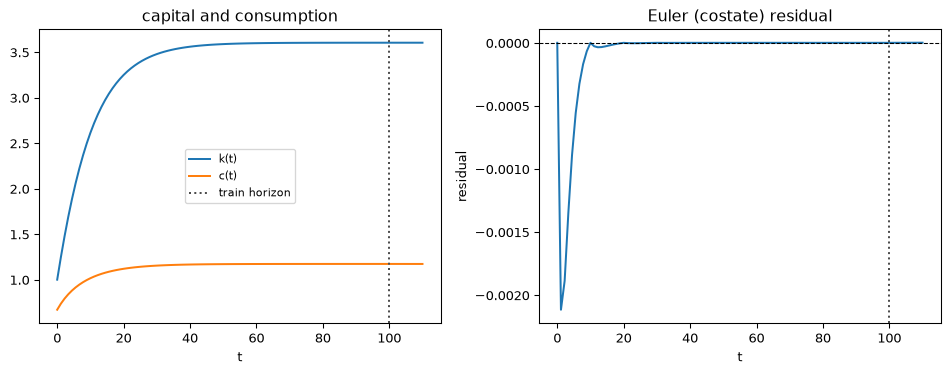

In [10]:
c_test = c_0 + K_tilde_test @ alpha_c

fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.plot(t_test, k_test, "C0", label="k(t)")
ax_k.plot(t_test, c_test, "C1", label="c(t)")
ax_k.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_k.set(xlabel="t", title="capital and consumption")
ax_k.legend(fontsize=8)
ax_r.plot(t_test, costate_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="Euler (costate) residual")
fig.tight_layout()
plt.show()